In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

| #  | Column                | الوصف                                                                            | نوع البيانات  |
| -- | --------------------- | -------------------------------------------------------------------------------- | ------------- |
| 1  | **Posted On**         | تاريخ نشر إعلان الإيجار                                                          | Date / Object |
| 2  | **BHK**               | عدد غرف النوم + المعيشة، مثل 1 BHK أو 2 BHK                                      | Integer       |
| 3  | **Rent**              | قيمة الإيجار الشهري للعقار                                                       | Float         |
| 4  | **Size**              | مساحة العقار بالـ Square Feet                                                    | Float         |
| 5  | **Floor**             | الدور الموجود فيه العقار وعدد أدوار المبنى                                       | Object        |
| 6  | **Area Type**         | نوع المنطقة حسب طريقة تصنيف المساحة، مثل Super Area أو Carpet Area أو Built Area | Categorical   |
| 7  | **Area Locality**     | اسم المنطقة أو الحي الذي يقع فيه العقار                                          | Categorical   |
| 8  | **City**              | المدينة التي يوجد بها العقار                                                     | Categorical   |
| 9  | **Furnishing Status** | حالة الأثاث: Furnished / Semi-Furnished / Unfurnished                            | Categorical   |
| 10 | **Tenant Preferred**  | نوع المستأجر المفضل، مثل Bachelors أو Family                                     | Categorical   |
| 11 | **Bathroom**          | عدد الحمامات في العقار                                                           | Float         |
| 12 | **Point of Contact**  | الشخص المسؤول عن التواصل بخصوص العقار، مثل Owner أو Agent                        | Categorical   |


In [ ]:
df = pd.read_csv('dataset/House_Rent_Dataset.csv')

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4746 entries, 0 to 4745
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Posted On          4746 non-null   object 
 1   BHK                4746 non-null   int64  
 2   Rent               4741 non-null   float64
 3   Size               4738 non-null   float64
 4   Floor              4746 non-null   object 
 5   Area Type          4739 non-null   object 
 6   Area Locality      4746 non-null   object 
 7   City               4746 non-null   object 
 8   Furnishing Status  4746 non-null   object 
 9   Tenant Preferred   4746 non-null   object 
 10  Bathroom           4742 non-null   float64
 11  Point of Contact   4746 non-null   object 
dtypes: float64(3), int64(1), object(8)
memory usage: 445.1+ KB


In [4]:
df.shape

(4746, 12)

In [5]:
df.describe()

,BHK,Rent,Size,Bathroom
count,4746.000000,4.741000e+03,4738.000000,4742.000000
mean,2.083860,3.502340e+04,967.936049,1.965837
std,0.832256,7.814214e+04,634.562635,0.884904
min,1.000000,1.200000e+03,10.000000,1.000000
25%,2.000000,1.000000e+04,550.000000,1.000000
50%,2.000000,1.600000e+04,850.000000,2.000000
75%,3.000000,3.300000e+04,1200.000000,2.000000
max,6.000000,3.500000e+06,8000.000000,10.000000


In [6]:
df.columns

Index(['Posted On', 'BHK', 'Rent', 'Size', 'Floor', 'Area Type',
       'Area Locality', 'City', 'Furnishing Status', 'Tenant Preferred',
       'Bathroom', 'Point of Contact'],
      dtype='object')

In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
df.isnull().sum().sort_values(ascending=False)

Size                 8
Area Type            7
Rent                 5
Bathroom             4
Posted On            0
BHK                  0
Area Locality        0
Floor                0
City                 0
Furnishing Status    0
Tenant Preferred     0
Point of Contact     0
dtype: int64

In [9]:
from sklearn.impute import SimpleImputer

impute = SimpleImputer(strategy='mean')

impute.fit(df[['Rent', 'Size', 'Bathroom']])

df[['Rent', 'Size', 'Bathroom']] = impute.transform(
    df[['Rent', 'Size', 'Bathroom']]
)

In [10]:
impute_cat = SimpleImputer(strategy='most_frequent')

df[['Area Type']] = impute_cat.fit_transform(
    df[['Area Type']]
)

In [11]:
df.isnull().sum()

Posted On            0
BHK                  0
Rent                 0
Size                 0
Floor                0
Area Type            0
Area Locality        0
City                 0
Furnishing Status    0
Tenant Preferred     0
Bathroom             0
Point of Contact     0
dtype: int64

In [ ]:
plt.figure(figsize=(8, 5))
import matplotlib.pyplot as plt
import seaborn as sns

sns.scatterplot(data=df, x='Size', y='Rent')
plt.title('Rent vs Size')
plt.tight_layout()
plt.show()

In [ ]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x='BHK', y='Rent')
plt.title('Rent vs BHK')
plt.tight_layout()
plt.show()

In [ ]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x='Furnishing Status', y='Rent')
plt.xticks(rotation=45)
plt.title('Rent vs Furnishing Status')
plt.tight_layout()
plt.show()

In [ ]:
plt.figure(figsize=(10, 8))
sns.heatmap(df.select_dtypes(include='number').corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()

In [16]:
lb = LabelEncoder()

In [17]:
X = df.drop('Rent', axis=1)
y = df['Rent']

In [18]:


X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [19]:
cols_to_drop = ['Posted On', 'Floor']
X_train = X_train.drop(columns=cols_to_drop)
X_test = X_test.drop(columns=cols_to_drop)

In [20]:
!pip install category_encoders
import  category_encoders as ce

'pip' is not recognized as an internal or external command,
operable program or batch file.


In [21]:
target_enc = ce.TargetEncoder(cols=['Area Locality'], smoothing=5)


X_train[['Area Locality']] = target_enc.fit_transform(
    X_train[['Area Locality']], y_train
)

In [22]:
X_test[['Area Locality']] = target_enc.transform(X_test[['Area Locality']])

In [23]:
cat_cols = [
    'Area Type',
    'City',
    'Furnishing Status',
    'Tenant Preferred',
    'Point of Contact',
]

X_train = pd.get_dummies(X_train, columns=cat_cols, drop_first=True)
X_test = pd.get_dummies(X_test, columns=cat_cols, drop_first=True)

In [24]:
X_train, X_test = X_train.align(X_test, join='left', axis=1, fill_value=0)

In [25]:
from sklearn.preprocessing import StandardScaler

In [26]:
scaler = StandardScaler()

In [27]:
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [28]:
model = LinearRegression()
model.fit(X_train_scaled, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [29]:
y_pred = model.predict(X_test_scaled)

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print('R2 Score:', r2_score(y_test, y_pred))
print('MAE:', mean_absolute_error(y_test, y_pred))
print('RMSE:', np.sqrt(mean_squared_error(y_test, y_pred)))

R2 Score: 0.5334331827022376
MAE: 22373.50796587274
RMSE: 43116.489151783324


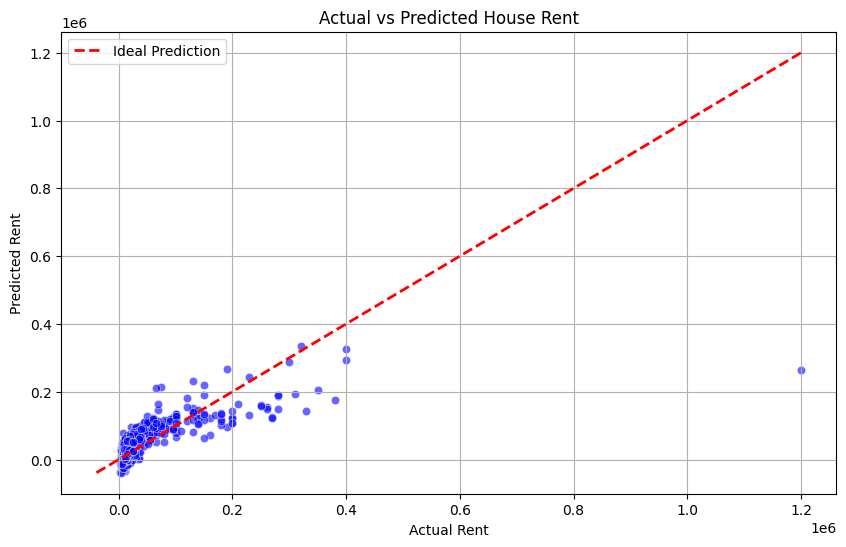

In [30]:
import matplotlib.pyplot as plt
import seaborn as sns

# رسم العلاقة بين القيم الحقيقية والمتوقعة
plt.figure(figsize=(10, 6))
sns.scatterplot(x=y_test, y=y_pred, alpha=0.6, color='blue')

# رسم خط التوقع المثالي (Actual = Predicted)
max_val = max(max(y_test), max(y_pred))
min_val = min(min(y_test), min(y_pred))
plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', linewidth=2, label='Ideal Prediction')

plt.xlabel('Actual Rent')
plt.ylabel('Predicted Rent')
plt.title('Actual vs Predicted House Rent')
plt.legend()
plt.grid(True)
plt.show()

In [31]:
#!python -m pip install numpy pandas matplotlib

In [32]:
#!python -m pip install xgboost

In [33]:
!python -m pip install  catboost  lightgbm


[notice] A new release of pip is available: 23.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [34]:
from sklearn.linear_model import LinearRegression, Lasso, Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (
    RandomForestRegressor, ExtraTreesRegressor, BaggingRegressor, 
    AdaBoostRegressor, GradientBoostingRegressor, HistGradientBoostingRegressor
)
from xgboost import XGBRegressor
from catboost import CatBoostRegressor
from lightgbm import LGBMRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import pandas as pd
import numpy as np

# 1. تعريف جميع الموديلات كما هي في الصورة
models = {
    "Linear Regression": LinearRegression(),
    "Lasso": Lasso(),
    "Ridge": Ridge(),
    "KNN": KNeighborsRegressor(n_neighbors=5, metric='minkowski', p=1),
    "SVM": SVR(kernel='linear', C=100, gamma=1),
    "Decision Tree": DecisionTreeRegressor(criterion='squared_error', max_depth=10),
    "Random Forest": RandomForestRegressor(n_estimators=50, criterion='squared_error', max_depth=10, random_state=42),
    "ExtraTrees": ExtraTreesRegressor(n_estimators=100, random_state=42),
    "Bagging": BaggingRegressor(estimator=DecisionTreeRegressor(criterion='squared_error', max_depth=10), n_estimators=15, random_state=42),
    "AdaBoost": AdaBoostRegressor(n_estimators=15, random_state=42),
    "GradientBoosting": GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, random_state=42),
    "HistGradientBoosting": HistGradientBoostingRegressor(max_iter=100, learning_rate=0.1, random_state=42),
    "XGBoost": XGBRegressor(n_estimators=100, learning_rate=0.1, random_state=42),
    "CatBoost": CatBoostRegressor(verbose=0, iterations=100, learning_rate=0.1, random_state=42),
    "LightGBM": LGBMRegressor(n_estimators=100, learning_rate=0.1, random_state=42)
}

results = []
all_preds = {}

# 2. تدريب الموديلات وتقييمها
for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    preds = model.predict(X_test_scaled)
    
    r2 = r2_score(y_test, preds)
    mae = mean_absolute_error(y_test, preds)
    rmse = np.sqrt(mean_squared_error(y_test, preds))
    
    all_preds[name] = preds
    results.append({'Model': name, 'R2 Score': r2, 'MAE': mae, 'RMSE': rmse})

# عرض نتائج مقارنة الموديلات في الجدول
results_df = pd.DataFrame(results).sort_values(by='R2 Score', ascending=False)
display(results_df)

c:\Users\DELL\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\linear_model\_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.340e+12, tolerance: 2.516e+09
  model = cd_fast.enet_coordinate_descent(


[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000729 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 557
[LightGBM] [Info] Number of data points in the train set: 3796, number of used features: 16
[LightGBM] [Info] Start training from score 35181.124757


,Model,R2 Score,MAE,RMSE
13,CatBoost,0.670373,12726.340635,36240.780064
12,XGBoost,0.661178,13781.464515,36742.820082
7,ExtraTrees,0.605137,12581.371749,39665.199916
5,Decision Tree,0.602796,16851.672299,39782.590104
3,KNN,0.596860,11407.687026,40078.765582
10,GradientBoosting,0.583091,14763.813996,40757.467509
11,HistGradientBoosting,0.546678,14691.482085,42500.111042
1,Lasso,0.539552,21627.453559,42832.820127
2,Ridge,0.537717,21864.357320,42918.079772
0,Linear Regression,0.533433,22373.507966,43116.489152


In [ ]:
plt.figure(figsize=(12, 6))
sns.barplot(data=results_df, x='R2 Score', y='Model', palette='viridis')
plt.title('Comparison of Regression Models Accuracy (R2 Score)')
plt.xlabel('R2 Score')
plt.ylabel('Model')
plt.xlim(min(0, results_df['R2 Score'].min()), 1)
plt.show()

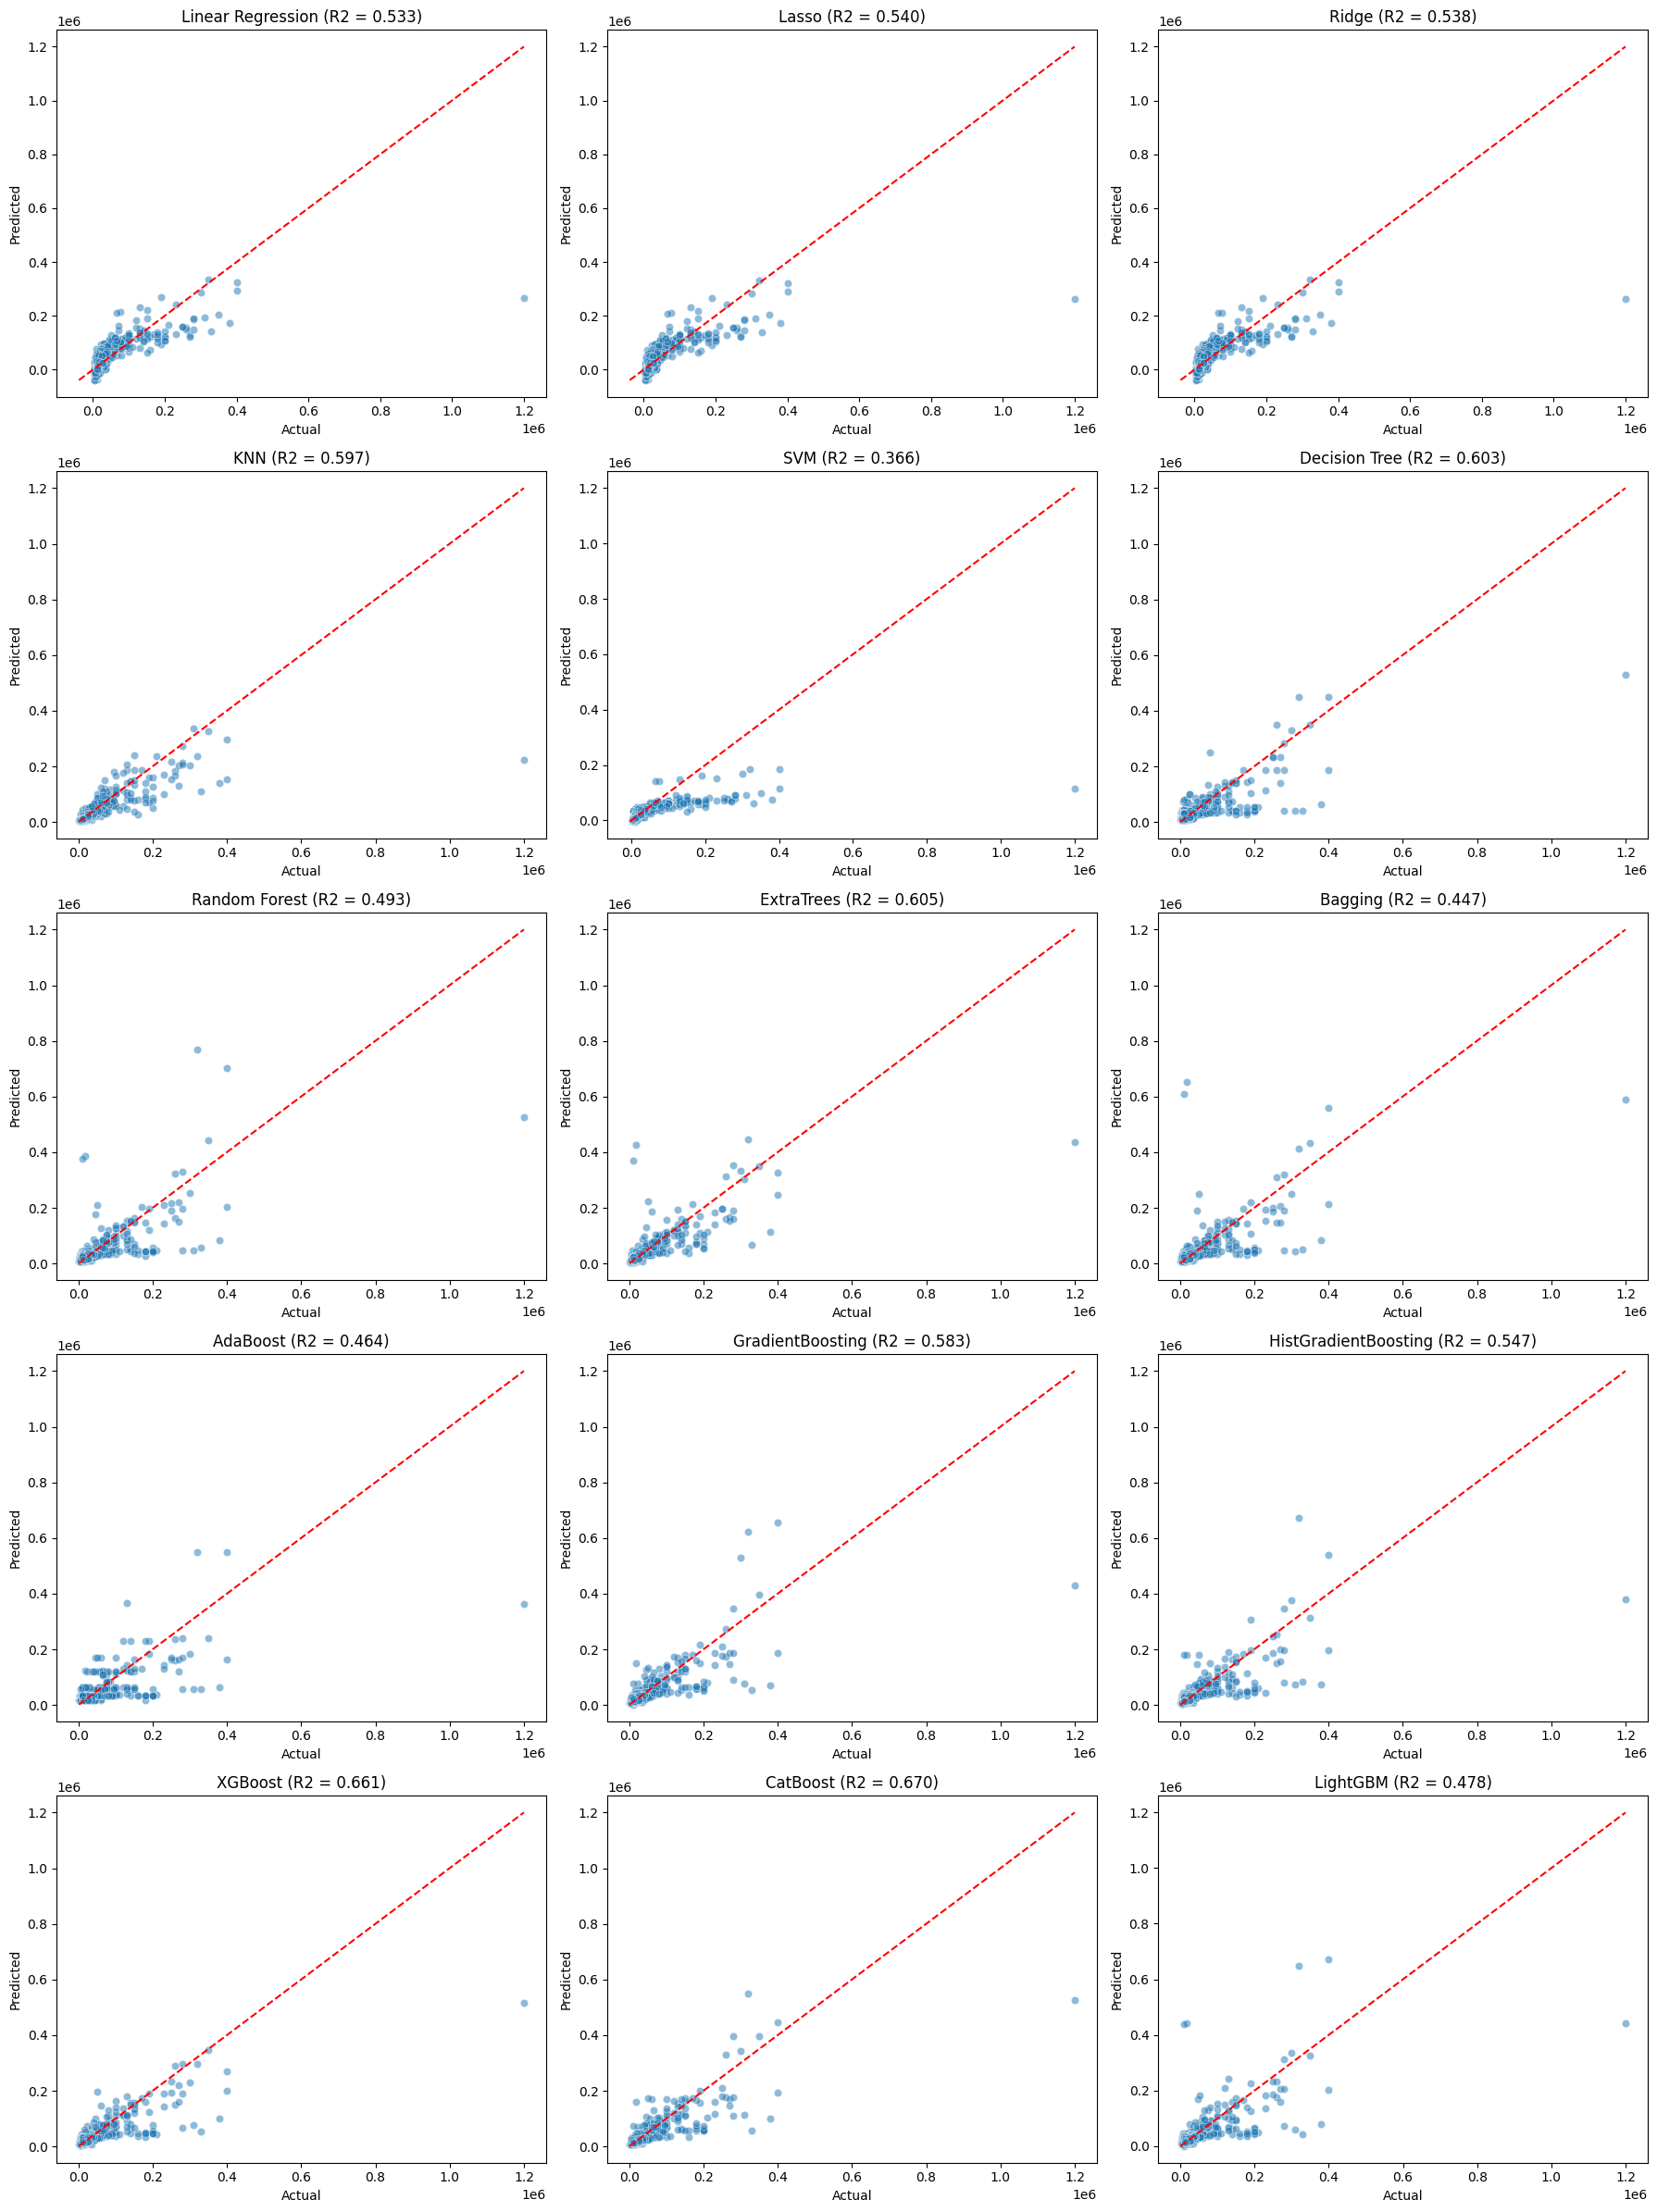

In [36]:
fig, axes = plt.subplots(5, 3, figsize=(18, 24))
axes = axes.flatten()

for i, (name, y_pred) in enumerate(all_preds.items()):
    sns.scatterplot(x=y_test, y=y_pred, alpha=0.5, ax=axes[i])
    low = min(np.min(y_test), np.min(y_pred))
    high = max(np.max(y_test), np.max(y_pred))
    axes[i].plot([low, high], [low, high], color='red', linestyle='--')
    axes[i].set_title(f"{name} (R2 = {r2_score(y_test, y_pred):.3f})")
    axes[i].set_xlabel('Actual')
    axes[i].set_ylabel('Predicted')

plt.tight_layout()
plt.show()

## Select the best model
We pick the best model using Cross Validation on the training set only (the test set is not touched).

In [ ]:
from sklearn.base import clone
from sklearn.model_selection import GridSearchCV, cross_val_score

cv_scores = {}
for name, m in models.items():
    cv_scores[name] = cross_val_score(clone(m), X_train_scaled, y_train, cv=3, scoring='r2', n_jobs=-1).mean()

cv_df = pd.DataFrame({'Model': list(cv_scores.keys()), 'CV R2': list(cv_scores.values())})
cv_df = cv_df.sort_values(by='CV R2', ascending=False).reset_index(drop=True)
cv_df

## GridSearchCV on the best model

In [ ]:
param_grids = {
    "Linear Regression": {},
    "Lasso": {"alpha": [0.01, 0.1, 1, 10]},
    "Ridge": {"alpha": [0.1, 1, 10, 100]},
    "KNN": {"n_neighbors": [3, 5, 7, 11], "weights": ["uniform", "distance"]},
    "SVM": {"C": [1, 10, 100]},
    "Decision Tree": {"max_depth": [5, 10, 15, None], "min_samples_split": [2, 10]},
    "Random Forest": {"n_estimators": [100, 200], "max_depth": [10, 20, None]},
    "ExtraTrees": {"n_estimators": [100, 200], "max_depth": [10, 20, None]},
    "Bagging": {"n_estimators": [15, 30, 50]},
    "AdaBoost": {"n_estimators": [50, 100], "learning_rate": [0.1, 1]},
    "GradientBoosting": {"n_estimators": [100, 200], "learning_rate": [0.05, 0.1], "max_depth": [3, 5]},
    "HistGradientBoosting": {"max_iter": [100, 200], "learning_rate": [0.05, 0.1]},
    "XGBoost": {"n_estimators": [100, 200], "learning_rate": [0.05, 0.1], "max_depth": [3, 6]},
    "CatBoost": {"iterations": [100, 300], "depth": [4, 6]},
    "LightGBM": {"n_estimators": [100, 200], "learning_rate": [0.05, 0.1], "num_leaves": [31, 63]},
}

best_name = cv_df.loc[0, 'Model']
print('Best model:', best_name)

grid = GridSearchCV(clone(models[best_name]), param_grids.get(best_name, {}), cv=3, scoring='r2', n_jobs=-1)
grid.fit(X_train_scaled, y_train)

print('best_params_:', grid.best_params_)
print('best_score_ :', grid.best_score_)

best_model = grid.best_estimator_

## Before vs after tuning (test set)

In [ ]:
base_model = clone(models[best_name])
base_model.fit(X_train_scaled, y_train)

rows = []
for label, m in [('Before tuning', base_model), ('After tuning', best_model)]:
    p = m.predict(X_test_scaled)
    rows.append({'Version': label,
                 'MAE': mean_absolute_error(y_test, p),
                 'RMSE': np.sqrt(mean_squared_error(y_test, p)),
                 'R2': r2_score(y_test, p)})
pd.DataFrame(rows)

## Final evaluation

In [ ]:
y_pred = best_model.predict(X_test_scaled)
residuals = np.array(y_test) - y_pred

print('MAE :', mean_absolute_error(y_test, y_pred))
print('MSE :', mean_squared_error(y_test, y_pred))
print('RMSE:', np.sqrt(mean_squared_error(y_test, y_pred)))
print('R2  :', r2_score(y_test, y_pred))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Actual vs Predicted
axes[0].scatter(y_test, y_pred, alpha=0.5)
low, high = min(np.min(y_test), np.min(y_pred)), max(np.max(y_test), np.max(y_pred))
axes[0].plot([low, high], [low, high], color='red', linestyle='--')
axes[0].set_title('Actual vs Predicted')
axes[0].set_xlabel('Actual')
axes[0].set_ylabel('Predicted')

# Residuals
axes[1].scatter(y_pred, residuals, alpha=0.5)
axes[1].axhline(0, color='red', linestyle='--')
axes[1].set_title('Residuals Plot')
axes[1].set_xlabel('Predicted')
axes[1].set_ylabel('Residual (Actual - Predicted)')

plt.tight_layout()
plt.show()

### Interpretation (generated automatically)

In [ ]:
# Plain-English summary, generated from the real results above
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)
avg_actual = np.mean(np.abs(y_test))

print(f"Best model: {best_name} with {grid.best_params_}")
print(f"- R2 = {r2:.3f}: the model explains about {r2*100:.1f}% of the variation in the target.")
print(f"- MAE = {mae:,.2f}: on average the prediction is off by this amount ({mae/avg_actual*100:.1f}% of the average actual value).")
if rmse > 1.5 * mae:
    print(f"- RMSE ({rmse:,.2f}) is much bigger than MAE, so there are some large errors (outliers) the model misses.")
else:
    print(f"- RMSE ({rmse:,.2f}) is close to MAE, so the errors are fairly even with no big outliers.")
print(f"- Mean residual = {residuals.mean():,.2f}: close to 0 means the model does not systematically over- or under-predict.")
print(f"- Tuning changed R2 from {rows[0]['R2']:.3f} to {rows[1]['R2']:.3f}.")